# Estado del arte: los enfoques de calibración de Tasche comparados sobre S&P 2010 y 2011

**Pregunta:** Cuando un banco debe llevar su curva de PD de 2009 a un año nuevo, ¿cuál de los nueve enfoques de Tasche pronostica mejor la PD y el patrón de incumplimientos que mostraron los corporativos de S&P en 2010 y 2011, y cuánto cuesta la elección en capital?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 05 y 07 de este tema (los enfoques y la función IRB)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar lo que dice la investigación sobre llevar una curva de PD a un período nuevo: el hallazgo de Tasche sobre el escalamiento y las demás prácticas que lista;
- reconstruir la curva de 2009 por ajuste cuasi de momentos y llevarla a 2010 y 2011 con los nueve enfoques, corriendo el motor sobre las tasas y perfiles versionados;
- comparar los enfoques por la PD que pronostica cada uno frente a la PD observada, por qué tan bien el perfil de incumplimiento implícito de cada curva sigue al observado, y por el ponderador de riesgo IRB que da cada uno;
- decir cuál comparación separa a los enfoques y cuál no, y por qué un año de 63 incumplimientos no puede ordenarlos todos;
- decir qué hace y qué no hace el producto en cada práctica.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import irb

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos archivos versionados del caso C05, la calibración de una curva de PD sobre las calificaciones corporativas de S&P de Tasche (2013) (clase de licencia `derived-only`, de modo que solo se versionan tasas, perfiles y resultados, nunca conteos por grado; https://doi.org/10.21314/jcr.2013.169): `data/derived/C05/sp-2010.json` y `data/derived/C05/sp-2011.json`. Cada uno contiene el perfil de calificaciones, las tasas de incumplimiento y la razón de precisión de 2009, el perfil de calificaciones y la PD observada del año de pronóstico (`outputs`), la curva de cada uno de los nueve enfoques (`outputs.approaches`), las pruebas versionadas (`tests`) y el impacto en capital (`impact`). Todo lo que el motor necesita está en las tasas y los perfiles, de modo que el notebook recalcula las curvas desde ellos y lee las pruebas, que necesitan conteos, tal como están versionadas.

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
years = {y: json.loads((C05 / f"sp-{y}.json").read_text(encoding="utf-8")) for y in (2010, 2011)}
base = years[2010]["outputs"]
grades = base["grades"]

## Método

### Paso 1: la curva de 2009, suavizada por ajuste cuasi de momentos

Los datos de un año dan una tasa de incumplimiento para cada uno de 17 grados, y la mayoría de los buenos grados no muestra ninguna. Una curva de PD las suaviza en una curva monótona que conserva la PD incondicional del año y su razón de precisión, el área bajo el perfil de precisión acumulado que mide qué tan bien las calificaciones separan a los deudores que incumplen de los que sobreviven. El ajuste cuasi de momentos (QMM) de Tasche ajusta una curva de dos parámetros a esos dos números (Tasche, 2013, sección 4). El `qmm` del motor toma el perfil de calificaciones, la PD, la razón de precisión y el perfil de sobrevivientes, que las tasas versionadas dan como $\pi^S_i \propto \pi_i (1 - \mathrm{pd}_i)$. La celda siguiente ajusta la curva de 2009 e imprime sus parámetros.

In [3]:
# Fit the 2009 curve by quasi moment matching from the committed profile, PD and accuracy ratio
profile0 = np.array(base["profile0"])
default_rate0 = np.array(base["default_rate0"])
survival0 = profile0 * (1 - default_rate0)
survival0 = survival0 / survival0.sum()
start = pc.qmm(base["profile0"], base["pd0"], base["ar0"], survival_profile=list(survival0))
curve0 = np.array(start["pd_curve"])

print(f"2009: PD {base['pd0']:.4f}, razón de precisión {base['ar0']:.4f}")
print(f"QMM: alpha {start['alpha']:.4f}, beta {start['beta']:.4f}")
print(f"PD de la curva del mejor y del peor grado: {curve0[0]:.6f}, {curve0[-1]:.4f}")
print(f"grados sin incumplimientos en 2009: {int((default_rate0 == 0).sum())} de {len(grades)}")

2009: PD 0.0399, razón de precisión 0.8271
QMM: alpha 5.2048, beta 2.1613
PD de la curva del mejor y del peor grado: 0.000028, 0.4835
grados sin incumplimientos en 2009: 6 de 17


La figura dibuja la tasa de incumplimiento observada de 2009 de cada grado como puntos, la curva suavizada como línea, y la proporción de deudores en cada grado como barras, con un eje logarítmico para las tasas.

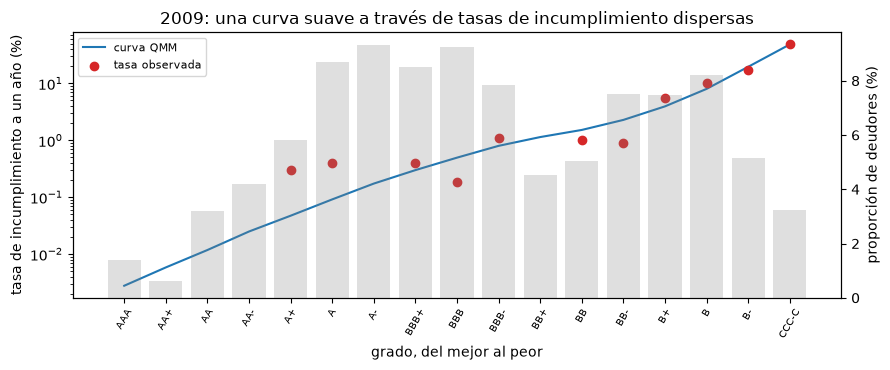

In [4]:
# Draw the 2009 default rates, the smoothed curve and the rating profile
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(grades))
seen = default_rate0 > 0
ax.plot(x, 100 * curve0, color="tab:blue", label="curva QMM")
ax.scatter(x[seen], 100 * default_rate0[seen], color="tab:red", zorder=3, label="tasa observada")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=60, fontsize=7)
ax.set_xlabel("grado, del mejor al peor")
ax.set_ylabel("tasa de incumplimiento a un año (%)")
share = ax.twinx()
share.bar(x, 100 * profile0, color="grey", alpha=0.25)
share.set_ylabel("proporción de deudores (%)")
ax.set_title("2009: una curva suave a través de tasas de incumplimiento dispersas")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

Los puntos rojos se dispersan alrededor de la curva y faltan en los seis mejores grados, donde ningún deudor incumplió: una tasa de cero no es una PD de cero, y la curva da a esos grados una PD pequeña positiva. Las barras grises muestran que los deudores se concentran entre A- y BB y otra vez en B, de modo que el comportamiento de la curva ahí, más que en cualquiera de los extremos, determina la PD incondicional. La figura no muestra que dos parámetros basten para todos los años; muestra que bastan para seguir los puntos de 2009 que existen.

### Paso 2: nueve maneras de llevar la curva a un año nuevo

Los enfoques de Tasche se ordenan según lo que el banco sabe cuando empieza el año nuevo. En el **caso 1** conoce el perfil de calificaciones nuevo y la PD: el perfil de incumplimiento invariante (A1), la razón de precisión invariante (A2), las PD escaladas (A3) y la razón de verosimilitud escalada (A4). En el **caso 2** conoce solo la PD bajo el perfil antiguo (B1, razón de verosimilitud invariante). En el **caso 3** conoce solo el perfil nuevo: la curva de PD invariante, es decir, la curva del año pasado sin cambios (C1), dos ajustes de perfiles condicionales invariantes (C2 por mínimos cuadrados, C3 por mínimo chi-cuadrado) y la razón de verosimilitud invariante con el perfil conocido (C4). La celda siguiente calcula las nueve curvas para 2010 y 2011 con las funciones de `pd_curve` del motor, y la PD que pronostica cada enfoque. Los casos 1 y 2 reciben la PD, así que para A1 a A4 es la observada; el caso 3 debe inferirla.

In [5]:
# Carry the 2009 curve to 2010 and 2011 with the nine approaches and read the PD each forecasts
curves, forecast = {}, {}
dp_start = pc.implied_default_profile(curve0, base["profile0"])
sv_start = pc.implied_survival_profile(curve0, base["profile0"])
for year, doc in years.items():
    o = doc["outputs"]
    p1, pd1 = o["profile1"], o["pd1"]
    new = {
        "A1-idp": pc.invariant_default_profile(o["default_profile0"], p1, pd1),
        "A2-iar": pc.invariant_accuracy_ratio(p1, pd1, o["ar0"]),
        "A3-spd": pc.scaled_pds(curve0, p1, pd1),
        "A4-slr": pc.scaled_likelihood_ratio(curve0, start["pd"], p1, pd1),
        "B1-ilr": pc.invariant_likelihood_ratio(curve0, start["pd"], pd_1=pd1),
        "C1-ipc": pc.invariant_pd_curve(curve0, p1),
        "C2-ls": pc.invariant_conditional_profiles(dp_start, sv_start, p1, fit="least_squares"),
        "C3-chi2": pc.invariant_conditional_profiles(dp_start, sv_start, p1, fit="least_chi2"),
        "C4-ilr": pc.invariant_likelihood_ratio(curve0, start["pd"], profile_1=p1),
    }
    curves[year] = {aid: np.array(r["pd_curve"]) for aid, r in new.items()}
    own = ("C2-ls", "C3-chi2", "C4-ilr")  # these infer the PD themselves
    forecast[year] = {a: r["pd"] if a in own else pc.unconditional_pd(r["pd_curve"], p1) for a, r in new.items()}
ids = list(curves[2010])
for year, doc in years.items():
    pd1 = doc["outputs"]["pd1"]
    print(f"{year}: PD observada {pd1:.4f}, incumplimientos {doc['outputs']['n_defaults']}")
    print("  pronóstico / observada:", {a[:2]: round(forecast[year][a] / pd1, 2) for a in ids})

2010: PD observada 0.0114, incumplimientos 63
  pronóstico / observada: {'A1': 1.0, 'A2': 1.0, 'A3': 1.0, 'A4': 1.0, 'B1': 1.36, 'C1': 3.78, 'C2': 4.21, 'C3': 4.69, 'C4': 4.71}
2011: PD observada 0.0075, incumplimientos 44
  pronóstico / observada: {'A1': 1.0, 'A2': 1.0, 'A3': 1.0, 'A4': 1.0, 'B1': 1.15, 'C1': 4.99, 'C2': 4.65, 'C3': 3.77, 'C4': 3.71}


La figura dibuja la PD pronosticada sobre la PD observada para cada enfoque, en ambos años. Una barra en uno es un pronóstico igual a lo observado.

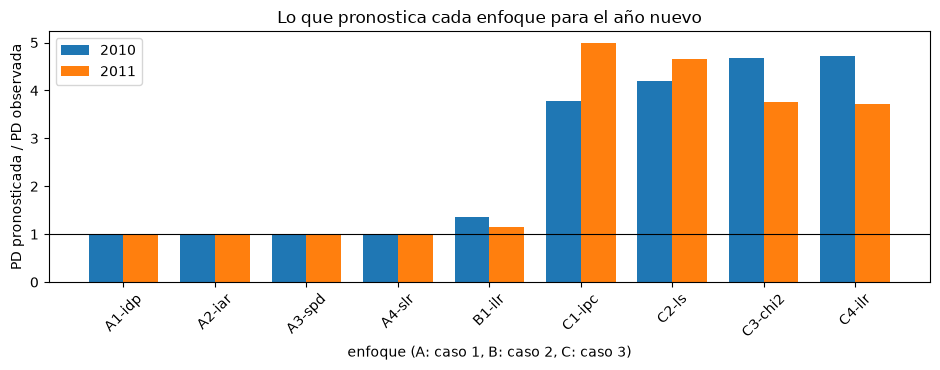

In [6]:
# Draw the forecast PD over the observed PD by approach, both years
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    ratio = [forecast[year][a] / years[year]["outputs"]["pd1"] for a in ids]
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, ratio, width, label=str(year))
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("enfoque (A: caso 1, B: caso 2, C: caso 3)")
ax.set_ylabel("PD pronosticada / PD observada")
ax.set_title("Lo que pronostica cada enfoque para el año nuevo")
ax.legend()
fig.tight_layout()
plt.show()

Las cuatro primeras barras son exactamente uno en ambos años porque a esos enfoques se les entrega la PD: no pueden equivocarse en ella. A B1 se le entrega la PD bajo el perfil antiguo y por eso queda algo sobre uno, cerca de 1,4 en 2010 y 1,15 en 2011. Los enfoques del caso 3 deben inferir la PD solo desde el perfil, y los cuatro se equivocan por un factor de cuatro a cinco en ambos años, en la misma dirección: parten de la PD de 2009 de 3,99% y el perfil no revela que el año fue más tranquilo. La figura dice que no conocer la PD es caro; no dice cuál de los enfoques del caso 3 es el menos malo, pues su orden se invierte entre los años.

## Estado del arte

### Lo que encontró la investigación, y lo que hace el producto

- **Escalar las PD es cuestionable.** Tasche (2013) muestra que multiplicar la curva de PD antigua por una constante, la práctica simple y extendida, es teóricamente cuestionable, y que la razón de precisión invariante por ajuste cuasi de momentos y la razón de verosimilitud escalada rinden mucho mejor. *Producto:* las cuatro se calculan arriba y se comparan abajo.
- **Llevar la curva antigua sin cambios.** La curva de PD invariante es lo que hace un banco cuando mantiene la calibración del año pasado. *Producto:* se calcula como C1 y se muestra su precio: una PD pronosticada varias veces la observada y el mayor ponderador de riesgo.
- **Otros peldaños.** La investigación lista la recalibración del intercepto, el escalamiento de Platt y la regresión isotónica como formas de calibrar los puntajes de un modelo a PD, y las previas bayesianas para carteras de bajo incumplimiento. *Producto:* estas trabajan sobre puntajes, no sobre un perfil de calificaciones, y quedan fuera de los enfoques comparados aquí; los intervalos de Jeffreys del notebook 02 son la posterior de una previa Beta, y no se ajusta ninguna previa adicional.
- **La comparación es un resultado de un año.** Dos años de pronóstico son dos muestras; las pruebas versionadas dicen qué enfoque es consistente con los incumplimientos del año, no cuál es correcto en general. El producto declara el límite y no ordena los enfoques más allá de él.

Cuatro lecturas comparan los enfoques en los dos años de pronóstico. La primera, la PD pronosticada frente a la observada, está en la figura de arriba. La segunda es la razón de precisión que implica cada curva bajo el perfil de calificaciones nuevo, frente a la observada en el año: cuánto del poder de ordenamiento de las calificaciones conserva la curva. La tercera pregunta si los incumplimientos cayeron sobre los grados como implica cada curva, comparando el perfil de incumplimiento que implica cada curva con el observado. La cuarta es el ponderador de riesgo IRB medio que da cada curva, que es lo que cuesta la elección en capital. Un año tiene 63 incumplimientos en 2010 y 44 en 2011 en 17 grados, y la mayoría de los grados tiene cero o uno: no cabe esperar que la tercera lectura separe todos los pares.

In [7]:
# The accuracy ratio each curve implies under the new rating profile, against the one observed in the year
ar_curve = {}
for year, doc in years.items():
    o = doc["outputs"]
    ar_curve[year] = {a: pc.accuracy_ratio_from_curve(curves[year][a], o["profile1"]) for a in ids}
    low, high = min(ar_curve[year].values()), max(ar_curve[year].values())
    print(f"{year}: razón de precisión observada {o['ar1']:.4f}, 2009 {o['ar0']:.4f}")
    print(f"{year}: nueve curvas, de {low:.4f} a {high:.4f}")

2010: razón de precisión observada 0.9015, 2009 0.8271
2010: nueve curvas, de 0.7935 a 0.8451
2011: razón de precisión observada 0.8867, 2009 0.8271
2011: nueve curvas, de 0.7753 a 0.8271


La razón de precisión del año subió de 0,8271 en 2009 a 0,9015 en 2010 y 0,8867 en 2011: las calificaciones separaron a los deudores que incumplen de los que sobreviven mejor que antes. Ninguna de las nueve curvas sigue esa alza. Implican razones entre 0,7935 y 0,8451 en 2010 y entre 0,7753 y 0,8271 en 2011, porque una curva llevada desde un año más grueso no puede reproducir la separación más nítida de un año con pocos incumplimientos. La razón de precisión invariante conserva el valor de 2009 por construcción, 0,8271, la mayor de las nueve en 2011. El poder de ordenamiento es así una lectura en que los enfoques quedan cerca entre sí y todos por debajo de lo observado, de modo que no favorece a los enfoques del caso 1 sobre los del caso 3.

In [8]:
# The default profile each curve implies under the new rating profile, against the observed one
distance, implied, observed = {}, {}, {}
for year, doc in years.items():
    o = doc["outputs"]
    seen = np.array(o["profile1"]) * np.array(o["default_rate1"])
    observed[year] = seen / seen.sum()
    implied[year] = {a: np.array(pc.implied_default_profile(curves[year][a], o["profile1"])) for a in ids}
    distance[year] = {a: float(np.abs(np.cumsum(implied[year][a]) - np.cumsum(observed[year])).max()) for a in ids}
    ranked = sorted(ids, key=distance[year].get)
    print(f"{year}: proporción de incumplimientos en el peor grado {observed[year][-1]:.3f}")
    print(f"{year}: mayor brecha, de menor a mayor")
    print("  ", ", ".join(f"{a[:2]} {distance[year][a]:.3f}" for a in ranked))

2010: proporción de incumplimientos en el peor grado 0.778
2010: mayor brecha, de menor a mayor
   A4 0.234, B1 0.247, A2 0.271, A1 0.325, A3 0.332, C1 0.332, C2 0.350, C3 0.361, C4 0.362
2011: proporción de incumplimientos en el peor grado 0.500
2011: mayor brecha, de menor a mayor
   A2 0.093, A4 0.122, B1 0.125, A1 0.134, C4 0.176, C3 0.177, C2 0.191, C1 0.200, A3 0.200


La figura dibuja el perfil de incumplimiento acumulado, grado por grado del mejor al peor, para los incumplimientos observados y para cuatro de las curvas: la curva de PD invariante (C1), las PD escaladas (A3), la razón de verosimilitud escalada (A4) y la razón de precisión invariante (A2).

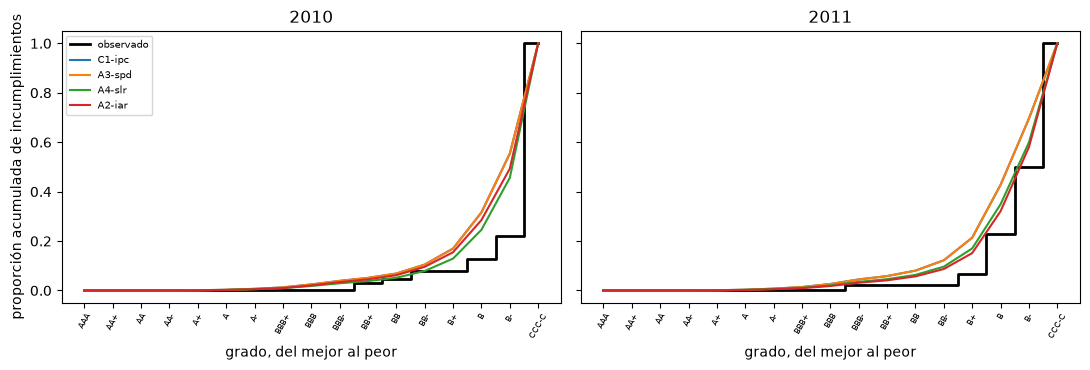

In [9]:
# Draw the cumulative default profile, observed and implied by four curves
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, year in zip(axes, years):
    ax.step(range(len(grades)), np.cumsum(observed[year]), where="mid", color="black", linewidth=2, label="observado")
    for a in ("C1-ipc", "A3-spd", "A4-slr", "A2-iar"):
        ax.plot(range(len(grades)), np.cumsum(implied[year][a]), label=a)
    ax.set_xticks(range(len(grades)))
    ax.set_xticklabels(grades, rotation=60, fontsize=6)
    ax.set_xlabel("grado, del mejor al peor")
    ax.set_title(str(year))
axes[0].set_ylabel("proporción acumulada de incumplimientos")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

En ambos años la escalera negra queda bajo todas las curvas hasta los últimos grados y luego salta: los incumplimientos se concentran en el peor grado, 78% de los 63 incumplimientos de 2010 y 50% de los 44 de 2011, más de lo que espera cualquier curva, y las curvas esperan más incumplimientos en los grados B que los ocurridos. En 2010 la razón de verosimilitud escalada (verde) queda más cerca de la escalera y las PD escaladas más lejos de las cuatro dibujadas. La línea azul de la curva de 2009 sin cambios queda oculta bajo la naranja de las PD escaladas: escalar una curva por una constante no cambia la forma de su perfil de incumplimiento, de modo que la forma sola no distingue a las dos, y solo su PD pronosticada, en la primera figura, lo hace. Las distancias impresas arriba son un número por curva, la mayor brecha entre las líneas acumuladas. Comparan solo formas; la prueba chi-cuadrado, que se lee a continuación, agrega cuántos incumplimientos había para ver la forma.

La prueba chi-cuadrado del perfil de incumplimiento implícito pregunta si los incumplimientos observados son consistentes con el perfil que implica cada curva. Es una prueba de Monte Carlo sobre conteos por grado, que no se versionan para esta clase de licencia, de modo que se lee de las `tests` versionadas y no se recalcula: su valor p y su luz para cada enfoque y año, y el error estándar de Monte Carlo de cada valor p. Un valor p bajo 5% pone la luz en ámbar.

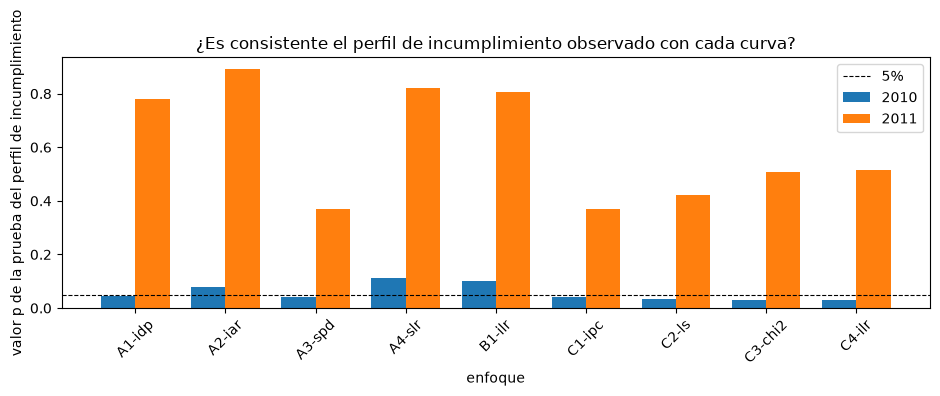

2010 pruebas calculadas con riskvalidation 1.0.1 | instalado 1.0.1
2010 p: {'A1': 0.046, 'A2': 0.079, 'A3': 0.042, 'A4': 0.111, 'B1': 0.101, 'C1': 0.042, 'C2': 0.034, 'C3': 0.029, 'C4': 0.029}
2010 ámbar o rojo: ['A1-idp', 'A3-spd', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr']
2011 pruebas calculadas con riskvalidation 1.0.1 | instalado 1.0.1
2011 p: {'A1': 0.782, 'A2': 0.891, 'A3': 0.37, 'A4': 0.82, 'B1': 0.808, 'C1': 0.37, 'C2': 0.421, 'C3': 0.51, 'C4': 0.515}
2011 ámbar o rojo: []
mayor error estándar de Monte Carlo de un valor p: 0.0016


In [10]:
# Draw the committed p-values of the default-profile test by approach and year
tests = {}
for year, doc in years.items():
    rows = [t for t in doc["tests"] if t["test_id"] == "pd.default_profile"]
    tests[year] = {t["model_id"]: t for t in rows}
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    values = [tests[year][a]["p_value"] for a in ids]
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, values, width, label=str(year))
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="5%")
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("enfoque")
ax.set_ylabel("valor p de la prueba del perfil de incumplimiento")
ax.set_title("¿Es consistente el perfil de incumplimiento observado con cada curva?")
ax.legend()
fig.tight_layout()
plt.show()
for year in years:
    amber = [a for a in ids if tests[year][a]["light"] != "green"]
    baked = years[year]["provenance"]["riskvalidation_version"]
    print(year, "pruebas calculadas con riskvalidation", baked, "| instalado", md.version("riskvalidation"))
    print(year, "p:", {a[:2]: round(tests[year][a]["p_value"], 3) for a in ids})
    print(year, "ámbar o rojo:", amber)
errors = [t["extras"]["mc_standard_error"] for y in tests for t in tests[y].values()]
print("mayor error estándar de Monte Carlo de un valor p:", round(max(errors), 4))

Las pruebas separan más a los años que a los enfoques. En 2011 todas las barras están sobre la línea punteada, de modo que las nueve curvas son consistentes con los 44 incumplimientos, y nada puede ordenarse. En 2010 seis quedan bajo ella, el perfil de incumplimiento invariante, las PD escaladas y los cuatro enfoques del caso 3, mientras que la razón de verosimilitud escalada, la razón de precisión invariante y el caso 2 se quedan sobre ella. Las PD escaladas tienen el menor valor p del caso 1 en ambos años, lo que concuerda con la advertencia de Tasche. El error de Monte Carlo de los valores p es pequeño junto a la diferencia de unas centésimas que separa a las barras cercanas a la línea, de modo que las luces ámbar no son ruido, pero con 63 incumplimientos casi todos en los últimos grados la prueba tiene poco más que decir para distinguir los enfoques del caso 1.

Ahora el costo en capital. La celda siguiente cotiza cada grado de cada curva con la función IRB del motor, bajo los supuestos del caso (Basilea III, corporativo, LGD 45%, vencimiento de 2,5 años, piso de PD de 0,05%), y promedia los ponderadores con el perfil de calificaciones del año de pronóstico.

In [11]:
# The average IRB risk weight of the forecast portfolio under each curve
spec = base["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
risk_weight, floored = {}, {}
for year, doc in years.items():
    mix = np.array(doc["outputs"]["profile1"])
    risk_weight[year], floored[year] = {}, {}
    for aid, curve in curves[year].items():
        results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in curve]
        risk_weight[year][aid] = float(mix @ np.array([r.risk_weight for r in results]))
        floored[year][aid] = sum(r.pd_applied != r.pd_input for r in results)
for year in years:
    anchored = [risk_weight[year][a] for a in ids[:5]]
    inferred = [risk_weight[year][a] for a in ids[5:]]
    print(f"{year}: casos 1 y 2 {min(anchored):.4f} a {max(anchored):.4f}")
    print(f"{year}: caso 3 {min(inferred):.4f} a {max(inferred):.4f}")
    print(f"{year}: dispersión de los cuatro del caso 1 {max(anchored[:4]) / min(anchored[:4]) - 1:.3f}")
    extra = [w / risk_weight[year]["A4-slr"] - 1 for w in inferred]
    print(f"{year}: caso 3 sobre la razón de verosimilitud escalada")
    print(f"  {min(extra):.3f} a {max(extra):.3f}")
print("grados en el piso de PD, 2010:", {a[:2]: floored[2010][a] for a in ids})

2010: casos 1 y 2 0.5504 a 0.6158
2010: caso 3 0.9068 a 0.9850
2010: dispersión de los cuatro del caso 1 0.107
2010: caso 3 sobre la razón de verosimilitud escalada
  0.648 a 0.790
2011: casos 1 y 2 0.4939 a 0.5347
2011: caso 3 0.8280 a 0.9263
2011: dispersión de los cuatro del caso 1 0.083
2011: caso 3 sobre la razón de verosimilitud escalada
  0.639 a 0.833
grados en el piso de PD, 2010: {'A1': 6, 'A2': 7, 'A3': 7, 'A4': 7, 'B1': 7, 'C1': 5, 'C2': 4, 'C3': 4, 'C4': 4}


La figura dibuja el ponderador de riesgo medio de cada enfoque en ambos años.

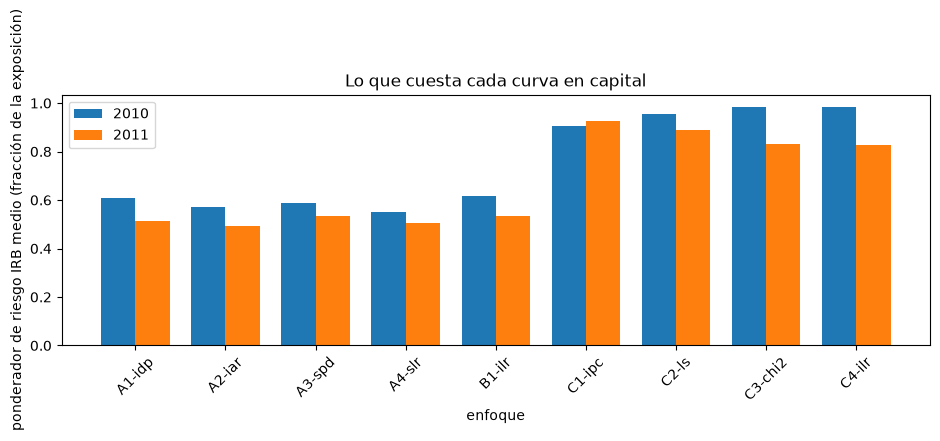

In [12]:
# Draw the average IRB risk weight by approach, both years
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, [risk_weight[year][a] for a in ids], width, label=str(year))
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("enfoque")
ax.set_ylabel("ponderador de riesgo IRB medio (fracción de la exposición)")
ax.set_title("Lo que cuesta cada curva en capital")
ax.legend()
fig.tight_layout()
plt.show()

Los cuatro enfoques del caso 1 y el caso 2 pesan entre 0,49 y 0,62, dentro de una décima de diferencia entre sí, de modo que la elección entre ellos mueve el capital mucho menos que la brecha con el grupo siguiente. Los enfoques del caso 3 pesan de 0,83 a 0,99, entre 64% y 83% más que la razón de verosimilitud escalada, porque sus PD pronosticadas son cuatro a cinco veces las observadas. El piso de PD obliga en los seis o siete mejores grados de toda curva anclada a la PD observada, de modo que esos grados pesan lo mismo con cualquier enfoque. La figura cotiza las curvas, no el año: no dice cuál será la PD verdadera de la cartera en los años siguientes.

## Resultados

**Respuesta:** Ningún enfoque gana en todas las lecturas, pero la razón de verosimilitud escalada (A4) es la que más se acerca al año 2010 y la razón de precisión invariante (A2) a 2011, mientras que los enfoques que deben inferir la PD fallan por un margen amplio. En 2010 los cuatro enfoques del caso 1 pronostican la PD observada de 0,0114 por construcción, el caso 2 pronostica 1,36 veces y los cuatro del caso 3 de 3,78 a 4,71 veces; en 2011, con una PD observada de 0,0075, el caso 2 pronostica 1,15 veces y el caso 3 de 3,71 a 4,99 veces. A4 tiene la menor brecha con el perfil de incumplimiento de 2010, 0,234, y un valor p de 0,111 frente a 0,029 a 0,046 de los seis enfoques en ámbar; en 2011 los nueve tienen valores p desde 0,370 y A2 tiene la menor brecha, 0,093. En capital el ponderador de riesgo IRB medio es de 0,5504 a 0,6158 en los casos 1 y 2 frente a 0,9068 a 0,9850 en el caso 3 en 2010, y de 0,4939 a 0,5347 frente a 0,8280 a 0,9263 en 2011.

- **Pronóstico frente a observado.** A los enfoques de los casos 1 y 2 se les da la PD, de modo que los cuatro del caso 1 son exactos y B1 es 1,36 veces la 0,0114 observada en 2010 y 1,15 veces la 0,0075 observada en 2011. Los enfoques del caso 3, que deben inferirla, parten de la PD de 2009 de 0,0399 y se pasan por un factor de cuatro a cinco en ambos años.
- **Poder de ordenamiento.** La razón de precisión subió de 0,8271 en 2009 a 0,9015 en 2010 y 0,8867 en 2011, y las nueve curvas implican de 0,7935 a 0,8451 y de 0,7753 a 0,8271: todas quedan por debajo.
- **El perfil de incumplimiento.** En 2010 el peor grado concentra 0,778 de los incumplimientos. A4, B1 y A2 son las curvas más cercanas (brechas de 0,234, 0,247 y 0,271) y las luces ámbar son A1, A3, C1, C2, C3 y C4 (p de 0,029 a 0,046); en 2011 ninguna luz es ámbar y los valores p van de 0,370 a 0,891. A3 y C1 tienen el mismo perfil de incumplimiento, de ahí la misma brecha (0,332 y 0,200) y el mismo valor p, y difieren solo en su PD. El error de Monte Carlo de cualquier valor p es a lo más 0,0016.
- **Capital.** Los cuatro ponderadores del caso 1 se dispersan en 0,107 en 2010 y 0,083 en 2011; el caso 3 pesa de 0,648 a 0,790 más que la razón de verosimilitud escalada en 2010 y de 0,639 a 0,833 más en 2011. El piso de PD obliga en 6 o 7 de los 17 grados bajo las curvas ancladas a la PD observada, de modo que los buenos grados pesan lo mismo con cualquier enfoque.
- **Lo que la comparación no puede decir.** Dos años de pronóstico son dos muestras, y la prueba del perfil de incumplimiento lee resultados versionados que necesitan conteos por grado, que la clase de licencia mantiene fuera del repositorio. La comparación muestra que no conocer la PD es caro y que un año no puede ordenar entre sí a los enfoques del caso 1 en general.

Lo que este notebook no muestra: cómo se construyen las curvas desde los objetivos de 2009 (notebook 05) ni cómo la función IRB convierte una PD en capital (notebook 07).

## Resumen

- Los enfoques que conocen el perfil y la PD del año ajustan los incumplimientos de 2010 mejor que escalar las PD o mantener la curva antigua; en 2011 nada los separa.
- No conocer la PD (caso 3) pronostica de cuatro a cinco veces la PD observada y cuesta de 64% a 83% más capital que la razón de verosimilitud escalada.
- La prueba chi-cuadrado ve la forma de una curva con pocos incumplimientos y no ordena los enfoques en general; el producto lo dice.
- Las prácticas de la investigación sobre puntajes (Platt, isotónica, intercepto) y las previas bayesianas no se corren aquí sobre un perfil de calificaciones.

**Qué probar después.** Reconstruye las curvas desde los objetivos de 2009 del notebook 05 y pregunta qué enfoque se habría elegido de antemano; luego lee el notebook 10.

## Referencias

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, Tablas 6 a 8 y secciones 4.2 a 4.4. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de los activos ponderados por riesgo (LGD, vencimiento y piso de PD). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Platt, J. (1999), Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods, in Advances in Large Margin Classifiers, MIT Press, por el peldaño que lista la investigación.